# 04. Statistical analysis

Phase 2, section 2.4. This notebook has two parts.

**Part A (below, task 2.4.2): time-series properties.** Autocorrelation, partial autocorrelation, stationarity and variance. These are properties of the series with no decision rule, and they do not depend on the hypotheses.

**Part B (tasks 2.4.1, 2.4.3): hypothesis tests.** Not run yet. The hypotheses, thresholds and methods are in the draft `docs/research/hypotheses.md`, which is waiting for review. The tests are added to this notebook only after that document is frozen.

The series has gaps (119 separate runs of consecutive days, the longest 158 days), so autocorrelations use only pairs of days that both exist and nothing is filled in. Everything describes associations in one station's data.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss

from aeron import timeseries as ts

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
# statsmodels warns about API changes and about KPSS p-values outside its table (bounded 0.01 to 0.10).
warnings.filterwarnings("ignore", message=".*currently returns a plain tuple.*")
warnings.filterwarnings("ignore", message=".*outside of the range of p-values.*")
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "savefig.bbox": "tight"}
)
WINTER = [11, 12, 1, 2]
SUMMER = [5, 6, 7, 8]


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")
    print("saved reports/figures/" + f"{name}.png")


daily = pd.read_csv(
    ROOT / "data" / "processed" / "daily_us_embassy.csv", index_col=0, parse_dates=True
)
grid = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
pm = daily["pm25_mean"].reindex(grid)  # NaN for days without a daily mean
log_pm = np.log(pm)
runs = ts.runs_of_observed(pm)
print(f"{int(pm.notna().sum())} days with a mean on a grid of {len(grid)} days")
print(
    f"{len(runs)} runs of consecutive days; longest: {runs.head(5).tolist()}; runs of 60 days or more: {int((runs >= 60).sum())}"
)

1823 days with a mean on a grid of 2282 days
119 runs of consecutive days; longest: [158, 80, 71, 51, 42]; runs of 60 days or more: 3


## 1. Autocorrelation and partial autocorrelation

The autocorrelation at lag k is the correlation between a day and the day k days earlier. The partial autocorrelation at lag k is what remains after the days in between are taken into account. They are computed on the log of the daily mean, separately for winter, summer and all days.

autocorrelation of the log daily mean
        winter (Nov-Feb)  summer (May-Aug)  all days
lag 1               0.64              0.77      0.76
lag 2               0.41              0.69      0.63
lag 3               0.31              0.65      0.57
lag 4               0.23              0.63      0.52
lag 5               0.20              0.63      0.52
lag 6               0.18              0.63      0.50
lag 7               0.22              0.66      0.53
lag 10              0.15              0.61      0.49
lag 14              0.12              0.61      0.48

partial autocorrelation
        winter (Nov-Feb)  summer (May-Aug)  all days
lag 1               0.64              0.77      0.76
lag 2              -0.00              0.24      0.11
lag 3               0.09              0.16      0.14
lag 4               0.01              0.14      0.09
lag 5               0.05              0.16      0.13
lag 6               0.03              0.12      0.07
lag 7               0.13            

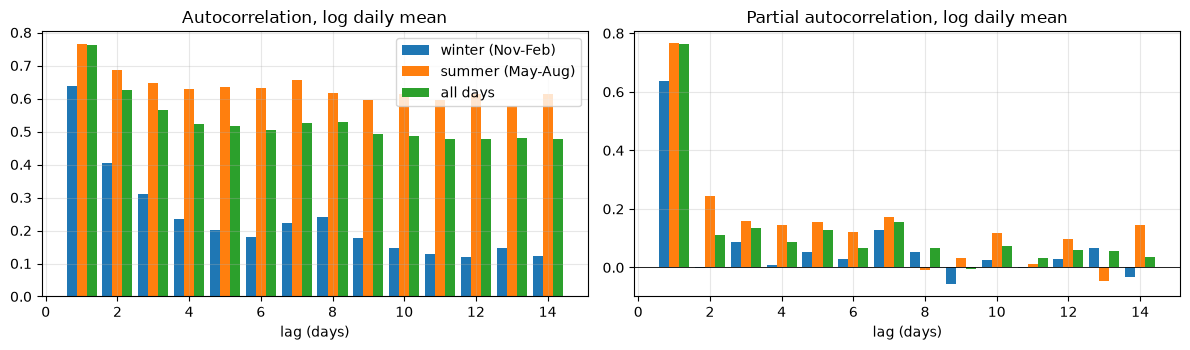

In [2]:
lags = 14
masks = {
    "winter (Nov-Feb)": pm.index.month.isin(WINTER),
    "summer (May-Aug)": pm.index.month.isin(SUMMER),
    "all days": np.ones(len(pm), bool),
}
acf, pacf, counts = {}, {}, {}
for name, mask in masks.items():
    x = log_pm.where(mask)
    acf[name] = ts.pairwise_acf(x, lags)
    pacf[name] = ts.pacf_from_acf(acf[name])
    counts[name] = int(x.notna().sum())
show = [1, 2, 3, 4, 5, 6, 7, 10, 14]
print("autocorrelation of the log daily mean")
print(
    pd.DataFrame(
        {k: v[[s - 1 for s in show]] for k, v in acf.items()},
        index=[f"lag {s}" for s in show],
    )
    .round(2)
    .to_string()
)
print("\npartial autocorrelation")
print(
    pd.DataFrame(
        {k: v[[s - 1 for s in show]] for k, v in pacf.items()},
        index=[f"lag {s}" for s in show],
    )
    .round(2)
    .to_string()
)
print("\ndays used:", counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
width = 0.28
for i, name in enumerate(masks):
    axes[0].bar(
        np.arange(1, lags + 1) + (i - 1) * width, acf[name], width=width, label=name
    )
    axes[1].bar(
        np.arange(1, lags + 1) + (i - 1) * width, pacf[name], width=width, label=name
    )
axes[0].set_title("Autocorrelation, log daily mean")
axes[1].set_title("Partial autocorrelation, log daily mean")
for ax in axes:
    ax.set_xlabel("lag (days)")
    ax.axhline(0, color="k", lw=0.6)
axes[0].legend()
plt.tight_layout()
save(fig, "acf_pacf_daily")

hourly autocorrelation, winter: {1: 0.91, 2: 0.82, 3: 0.74, 6: 0.59, 12: 0.44, 24: 0.47, 48: 0.27, 72: 0.24, 96: 0.2}
saved reports/figures/acf_hourly.png


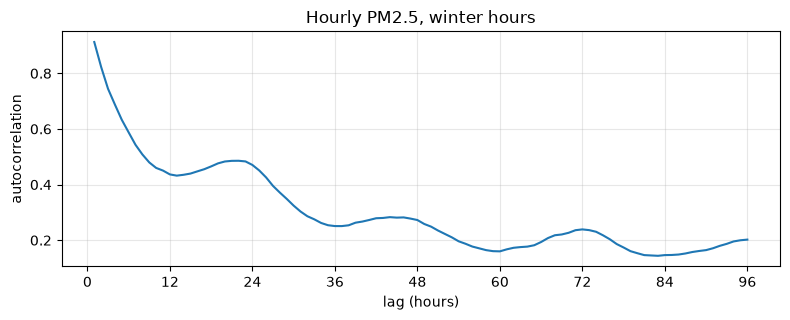

In [3]:
# Hourly autocorrelation (winter hours), showing the daily cycle.
hourly = pd.read_csv(
    ROOT / "data" / "processed" / "hourly_us_embassy.csv", index_col=0, parse_dates=True
)
hourly.index = hourly.index.tz_localize(None)
hp = hourly["pm25"]
winter_hours = hp.where(hp.index.month.isin(WINTER))
acf_h = ts.pairwise_acf(winter_hours, 96)
print(
    "hourly autocorrelation, winter:",
    {k: round(float(acf_h[k - 1]), 2) for k in (1, 2, 3, 6, 12, 24, 48, 72, 96)},
)
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(range(1, 97), acf_h)
ax.set_xticks(range(0, 97, 12))
ax.set_xlabel("lag (hours)")
ax.set_ylabel("autocorrelation")
ax.set_title("Hourly PM2.5, winter hours")
plt.tight_layout()
save(fig, "acf_hourly")

In [4]:
# How many independent days are 690 autocorrelated winter days worth?
winter_log = log_pm.where(pm.index.month.isin(WINTER))
acf_long = ts.pairwise_acf(winter_log, 30)
n_winter = int(winter_log.notna().sum())
ess = ts.effective_sample_size(n_winter, acf_long)
first_small = next((k for k, v in enumerate(acf_long, start=1) if v <= 0.05), None)
print(
    f"winter days: {n_winter}; autocorrelation first at or below 0.05 at lag {first_small}"
)
print(
    f"effective sample size: about {ess:.0f} independent days, so roughly {n_winter / ess:.0f} days per independent observation"
)
print(
    "winter autocorrelation at lags 7, 10, 14, 21:",
    [round(float(acf_long[k - 1]), 2) for k in (7, 10, 14, 21)],
)

winter days: 690; autocorrelation first at or below 0.05 at lag 25
effective sample size: about 74 independent days, so roughly 9 days per independent observation
winter autocorrelation at lags 7, 10, 14, 21: [0.22, 0.15, 0.12, 0.08]


## 2. Stationarity

A series is stationary if its average level and spread do not drift over time. The seasonal cycle already says the raw series is not. Two standard tests are used here, and they ask opposite questions:

- **Augmented Dickey-Fuller (ADF):** the null hypothesis is that the series has a unit root (is non-stationary). A small p-value suggests stationary.
- **KPSS:** the null hypothesis is that the series is stationary. A small p-value suggests non-stationary.

The longest unbroken stretches are short (158 days at most), so the tests have little power and only describe those stretches. For a longer view the daily values are averaged to weekly means (at least 5 days with data in the week), which have unbroken runs of up to 40 weeks. "Deseasonalised" means the log value minus the smoothed day-of-year average.

In [5]:
clim = ts.seasonal_climatology(log_pm)
deseason = log_pm - clim.reindex(log_pm.index.day_of_year).to_numpy()


def weekly(series):
    grouped = series.resample("W")
    return grouped.mean().where(grouped.count() >= 5)


def longest_stretch(series):
    observed = series.notna().astype(int)
    run_id = (observed.diff() != 0).cumsum()
    runs_ = observed.groupby(run_id).agg(["first", "size"])
    best = runs_[runs_["first"] == 1]["size"].idxmax()
    return series[run_id == best].dropna()


rows = []
candidates = {
    "weekly mean of log PM2.5": weekly(log_pm),
    "weekly mean, deseasonalised": weekly(deseason),
    "daily log PM2.5": log_pm,
    "daily log PM2.5, deseasonalised": deseason,
}
for label, series in candidates.items():
    z = longest_stretch(series)
    adf_p = adfuller(z, autolag="AIC")[1]
    kpss_p = kpss(z, regression="c", nlags="auto")[1]
    if adf_p < 0.05 and kpss_p >= 0.05:
        verdict = "consistent with stationary"
    elif adf_p >= 0.05 and kpss_p < 0.05:
        verdict = "consistent with non-stationary"
    else:
        verdict = "tests disagree"
    rows.append(
        {
            "series": label,
            "longest unbroken stretch": f"{z.index.min().date()} to {z.index.max().date()}",
            "n": len(z),
            "ADF p": adf_p,
            "KPSS p (capped at 0.1)": kpss_p,
            "reading": verdict,
        }
    )
pd.DataFrame(rows).set_index("series").round(3)

,longest unbroken stretch,n,ADF p,KPSS p (capped at 0.1),reading
series,,,,,
weekly mean of log PM2.5,2019-10-20 to 2020-07-19,40,0.384,0.016,consistent with non-stationary
"weekly mean, deseasonalised",2019-10-20 to 2020-07-19,40,0.001,0.100,consistent with stationary
daily log PM2.5,2024-02-02 to 2024-07-08,158,0.077,0.010,consistent with non-stationary
"daily log PM2.5, deseasonalised",2024-02-02 to 2024-07-08,158,0.000,0.010,tests disagree


In [6]:
# A second stretch for the daily log series: the longest unbroken stretch inside the warm half-year.
summer_log = log_pm.where(pm.index.month.isin([5, 6, 7, 8, 9]))
z = longest_stretch(summer_log)
print(
    f"daily log PM2.5, May to September: {z.index.min().date()} to {z.index.max().date()}, n = {len(z)}, ADF p = {adfuller(z, autolag='AIC')[1]:.3f}, KPSS p = {kpss(z, regression='c', nlags='auto')[1]:.3f}"
)

daily log PM2.5, May to September: 2023-07-15 to 2023-09-30, n = 78, ADF p = 0.000, KPSS p = 0.100


## 3. Does the spread depend on the level?

If the spread of daily values grows with their level, modelling the raw values treats clean and polluted periods unequally, and a log transformation can help. Each point is a month with at least 15 days of data.

months used: 68
correlation of the monthly mean and standard deviation: raw 0.88, log 0.32
saved reports/figures/variance_vs_level.png


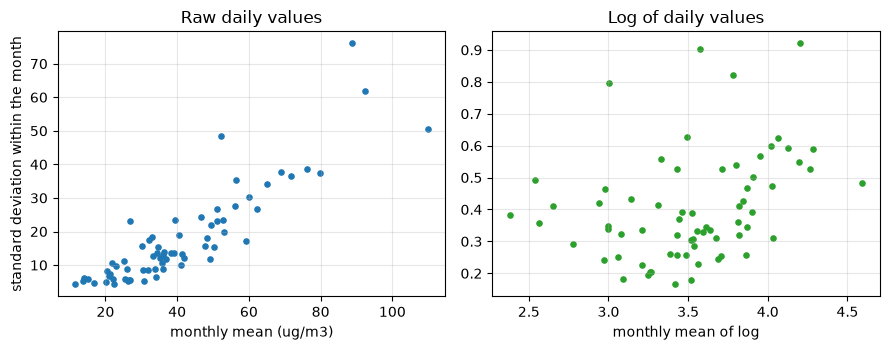

In [7]:
monthly = pd.DataFrame(
    {
        "mean": pm.groupby([pm.index.year, pm.index.month]).mean(),
        "std": pm.groupby([pm.index.year, pm.index.month]).std(),
        "n": pm.groupby([pm.index.year, pm.index.month]).count(),
    }
)
monthly_log = pd.DataFrame(
    {
        "mean": log_pm.groupby([pm.index.year, pm.index.month]).mean(),
        "std": log_pm.groupby([pm.index.year, pm.index.month]).std(),
        "n": log_pm.groupby([pm.index.year, pm.index.month]).count(),
    }
)
monthly, monthly_log = monthly[monthly["n"] >= 15], monthly_log[monthly_log["n"] >= 15]
print(f"months used: {len(monthly)}")
print(
    f"correlation of the monthly mean and standard deviation: raw {monthly['mean'].corr(monthly['std']):.2f}, log {monthly_log['mean'].corr(monthly_log['std']):.2f}"
)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(monthly["mean"], monthly["std"], s=14)
axes[0].set_xlabel("monthly mean (ug/m3)")
axes[0].set_ylabel("standard deviation within the month")
axes[0].set_title("Raw daily values")
axes[1].scatter(monthly_log["mean"], monthly_log["std"], s=14, color="tab:green")
axes[1].set_xlabel("monthly mean of log")
axes[1].set_title("Log of daily values")
plt.tight_layout()
save(fig, "variance_vs_level")

## 4. What this means for modelling and for the tests

All numbers are from the cells above (US station, 1,823 days with a daily mean in 119 unbroken runs, longest 158 days). They are properties of this one series.

**Persistence.** In winter the log daily mean is correlated 0.64 with the previous day, 0.41 two days back, 0.31 three days back, about 0.2 at five to seven days and 0.12 at 14 days. The partial autocorrelation is 0.64 at lag 1 and no larger than 0.13 at any later lag up to 14 (0.13 at lag 7, about 0 at lag 2). That is the pattern of a short memory of about one day on top of a slower background level. Yesterday's value, a few earlier days and a weekly mean should carry most of the information the series' own history can give. Whether longer lag windows help is a Phase 3 question (the lag window comparison for RQ3). In summer the correlation stays near 0.6 even at 14 days, which reflects slowly changing levels and differences between summers and not short-lived events.

**Hourly memory.** In winter the hourly autocorrelation is 0.91 at 1 hour, 0.59 at 6 hours, 0.44 at 12 hours, 0.47 at 24 hours (the daily cycle), 0.27 at 48 hours and 0.24 at 72 hours. The series' own history says little about hourly values two or three days ahead, which matches the earlier result that persistence is weak at 48 and 72 hours.

**Effective sample size.** The 690 winter days are worth roughly 74 independent days (about 9 days per independent observation). Formulas that treat days as independent would give intervals about three times too narrow. This is why the hypothesis tests use block bootstrap intervals. The winter autocorrelation is 0.12 at 14 days and 0.08 at 21 days, so blocks of 14 days leave a little dependence and the planned 28-day sensitivity run is justified.

**Stationarity.** The tests agree with what the monthly pattern shows. The weekly mean of the log is consistent with non-stationary (ADF p = 0.38, KPSS p = 0.016) and the deseasonalised weekly series is consistent with stationary (ADF p = 0.001, KPSS p at its upper bound of 0.10), but only over the longest unbroken stretch of 40 weeks (October 2019 to July 2020). On the longest daily stretch (158 days, February to July 2024) the raw log is consistent with non-stationary, and the deseasonalised log gives conflicting answers (ADF p below 0.001 suggests stationary, KPSS p = 0.01 rejects stationarity), which can point to a level shift within that stretch. A 78-day warm-season stretch in 2023 is consistent with stationary. With stretches this short the tests have little power and cannot say whether the level changes slowly across years. KPSS p-values are bounded between 0.01 and 0.10 by the test's tables.

**Spread and level.** Across 68 months, the monthly standard deviation moves with the monthly mean (correlation 0.88 on the raw values), and much less after taking logs (0.32). The log scale roughly equalises the spread.

**Implications for modelling**
- Use the seasonal cycle explicitly (month or day-of-year features) and report results per season and per winter. Methods that assume a constant mean over the years do not fit this series.
- Try the log of PM2.5 as a target in Phase 3 and compare it with the raw target, but report errors in ug/m3 as well, because the health thresholds are in ug/m3.
- Use lags of 1 to 3 days and a 7-day mean as the first lag features, then test longer windows.
- Models that need an unbroken series (classical ARIMA or state-space models) are awkward here, because the longest unbroken stretch is 158 days. Tree models with lag features can handle missing values directly. This is a practical note and does not show that any model is best.
- Differences between winters are part of the data. They are tested as H1 and affect how forecast skill should be reported.


## Part B: hypothesis tests

Not run. They wait for the review of `docs/research/hypotheses.md`. Once the hypotheses, thresholds and block length are frozen, the tests for H1 to H5 are added here, followed by the summary in `reports/data_analysis/`.